In [12]:
import pandas as pd
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt

### Visualisation des bâtiments stratégiques de Donges

Extraction des bâtiments stratégiques depuis le Cloud en cours...
Extraction terminée et sauvegardée dans data/processed/ !
Génération de la carte...


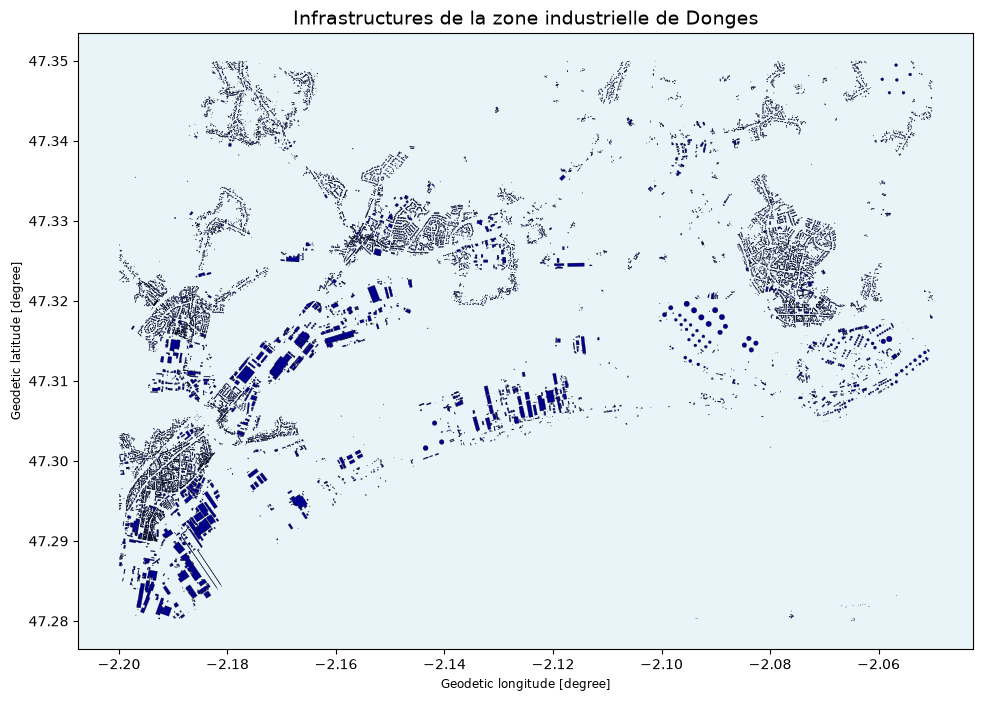

In [ ]:
# 1. Connexion et chargement
con = duckdb.connect('../projet_geoint.duckdb')
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("INSTALL httpfs; LOAD httpfs;")

# Paramètre de sécurité AWS/S3 pour orienter DuckDB
con.execute("SET s3_region='us-west-2';")

print("Extraction des bâtiments stratégiques depuis le Cloud en cours...")

# 2. La requête avec la version à jour d'Overture (2026-09-23.1)
query = """
COPY (
    SELECT 
        id,
        names.primary AS nom,
        height AS hauteur,
        geometry AS geom
    FROM read_parquet('s3://overturemaps-us-west-2/release/2026-09-23.1/theme=buildings/type=building/*', filename=true, hive_partitioning=1)
    WHERE bbox.xmin > -2.20 AND bbox.xmax < -2.05
      AND bbox.ymin > 47.28 AND bbox.ymax < 47.35
) TO '../data/processed/infrastructures_donges.parquet' (FORMAT PARQUET);
"""

con.execute(query)
print("Extraction terminée et sauvegardée dans data/processed/ !")

# 3. Visualisation
print("Génération de la carte...")
gdf_buildings = gpd.read_parquet('../data/processed/infrastructures_donges.parquet')

fig, ax = plt.subplots(figsize=(12, 8))
gdf_buildings.plot(ax=ax, color='darkblue', edgecolor='black', linewidth=0.2)
ax.set_title("Infrastructures de la zone industrielle de Donges", fontsize=14)
ax.set_facecolor('#e8f4f8')
plt.show()

### Visualisation des zones inondables en Région Pays de la Loire

Chargement du fichier GeoJSON en cours...
Le fichier contient 7 zones géographiques.
Voici les premières lignes de la base de données :


,geo_point_2d,gml_id,territoire,geometry
0,"{'lon': -2.377216985236118, 'lat': 47.30685881...",r_tri_s_r52.2,Saint Nazaire-Presqu'île de Guérande,"POLYGON ((-2.18141 47.3057, -2.18157 47.30528,..."
1,"{'lon': -0.15646481580148552, 'lat': 47.363203...",r_tri_s_r52.6,Angers-Authion-Saumur,"POLYGON ((0.28795 47.2285, 0.28723 47.22835, 0..."
2,"{'lon': -1.6230219254153622, 'lat': 47.2075633...",r_tri_s_r52.3,Nantes,"POLYGON ((-1.41223 47.17737, -1.41285 47.17694..."
3,"{'lon': 0.18803105294457212, 'lat': 47.9804442...",r_tri_s_r52.1,Le Mans,"POLYGON ((0.25506 47.9806, 0.25507 47.98051, 0..."
4,"{'lon': -1.791554591467056, 'lat': 47.91079052...",r_tri_s_r52.7,Vilaine de Rennes à Redon,"POLYGON ((-1.36575 48.12521, -1.36618 48.12452..."


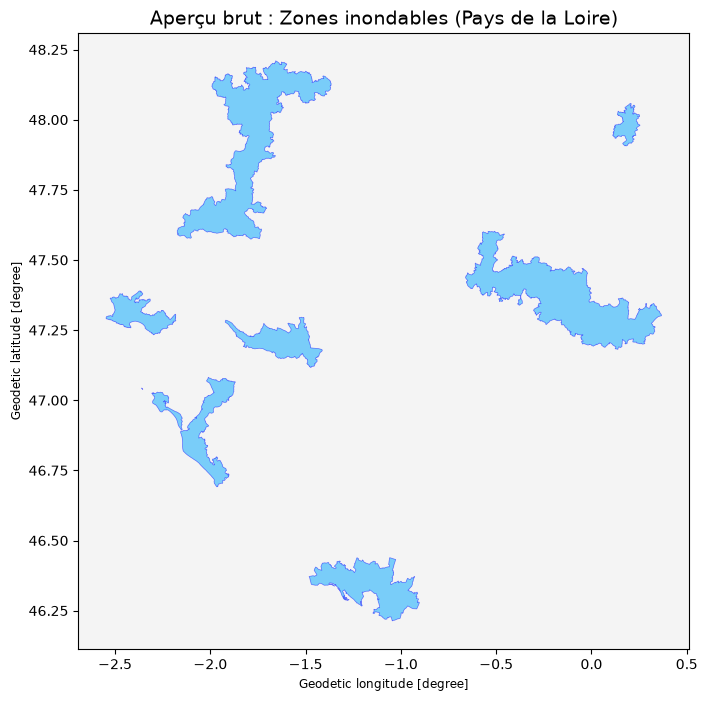

In [14]:
print("Chargement du fichier GeoJSON en cours...")
chemin_geojson = '../data/raw/234400034_tri-territoires-a-risque-important-dinondation-en-pays-de-la-loire.geojson'

# 1. Chargement avec GeoPandas
gdf_inondations = gpd.read_file(chemin_geojson)

# On le sauvegarde au format Parquet (ultra-léger et rapide)
gdf_inondations.to_parquet('../data/processed/inondations.parquet')

# 2. Afficher les premières lignes de la table de données
print(f"Le fichier contient {len(gdf_inondations)} zones géographiques.")
print("Voici les premières lignes de la base de données :")
display(gdf_inondations.head()) # 'display' formate joliment les tableaux dans VS Code

# 3. Afficher la carte globale du GeoJSON
fig, ax = plt.subplots(figsize=(10, 8))
gdf_inondations.plot(ax=ax, color='#00a8ff', alpha=0.5, edgecolor='blue', linewidth=0.5)

ax.set_title("Aperçu brut : Zones inondables (Pays de la Loire)", fontsize=14)
ax.set_facecolor('#f4f4f4')
plt.show()

### Visualisation des infrastructures en zones inondables

Croisement spatial en cours avec DuckDB...
Croisement terminé ! Les bâtiments menacés ont été isolés.
Génération de la carte de vulnérabilité...
Bilan de l'opération : 3450 infrastructures se trouvent en zone de vulnérabilité climatique.


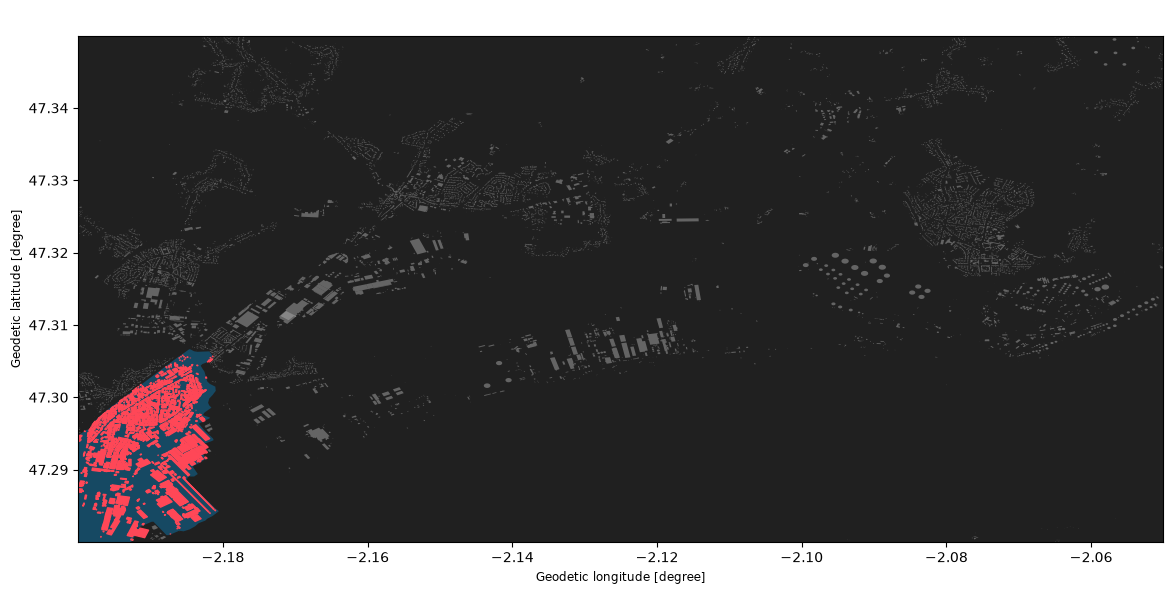

In [11]:
# 1. Connexion à notre moteur local
con = duckdb.connect('../projet_geoint.duckdb')
con.execute("INSTALL spatial; LOAD spatial;")

print("Croisement spatial en cours avec DuckDB...")

# 2. Le cœur du GEOINT : La jointure spatiale
# On compare les bâtiments avec le GeoJSON des inondations.
# Le "DISTINCT" évite de compter deux fois un bâtiment s'il chevauche deux zones inondables.
query_geoint = """
COPY (
    SELECT DISTINCT
        b.id,
        b.nom,
        b.geom
    FROM read_parquet('../data/processed/infrastructures_donges.parquet') AS b
    JOIN st_read('../data/raw/234400034_tri-territoires-a-risque-important-dinondation-en-pays-de-la-loire.geojson') AS s
      ON ST_Intersects(b.geom, ST_SetCRS(s.geom, 'OGC:CRS84'))
) TO '../data/processed/batiments_menaces.parquet' (FORMAT PARQUET);
"""
con.execute(query_geoint)
print("Croisement terminé ! Les bâtiments menacés ont été isolés.")

# 3. Cartographie (Le livrable final)
print("Génération de la carte de vulnérabilité...")

# On charge nos couches de base
gdf_inondations = gpd.read_file('../data/raw/234400034_tri-territoires-a-risque-important-dinondation-en-pays-de-la-loire.geojson')
gdf_all_buildings = gpd.read_parquet('../data/processed/infrastructures_donges.parquet')

# Chargement SÉCURISÉ des bâtiments menacés via Pandas
df_menaces = pd.read_parquet('../data/processed/batiments_menaces.parquet')

# On vérifie si DuckDB a trouvé des bâtiments en danger ou si le fichier est vide
if df_menaces.empty:
    print("Bonne nouvelle : Aucun bâtiment n'est menacé dans cette zone !")
    gdf_menaces = gpd.GeoDataFrame() # On crée une couche vide
else:
    # On convertit explicitement la colonne binaire 'geom' en vraie géométrie
    gdf_menaces = gpd.GeoDataFrame(df_menaces, geometry=gpd.GeoSeries.from_wkb(df_menaces['geom']))

# --- Paramétrage de la carte ---
fig, ax = plt.subplots(figsize=(14, 10))
ax.set_facecolor('#202020') # Fond sombre type "dashboard" GEOINT

# Couche 1 : Tous les bâtiments (en gris clair)
gdf_all_buildings.plot(ax=ax, color='#a9a9a9', alpha=0.5)

# Couche 2 : La zone de submersion (en bleu transparent)
gdf_inondations.plot(ax=ax, color='#00a8ff', alpha=0.3, edgecolor='none')

# Couche 3 : Les bâtiments en danger (en rouge vif !)
if not gdf_menaces.empty:
    gdf_menaces.plot(ax=ax, color='#ff4757', edgecolor='#ff4757', linewidth=1)
    print(f"Bilan de l'opération : {len(gdf_menaces)} infrastructures se trouvent en zone de vulnérabilité climatique.")

ax.set_title("GEOINT Climatique : Vulnérabilité des infrastructures (Estuaire de la Loire)", fontsize=16, color='white', fontweight='bold')

# Zoom sur la zone d'étude
minx, miny, maxx, maxy = gdf_all_buildings.total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

# Sauvegarde de la carte en haute résolution dans le dossier assets
plt.savefig('../assets/carte_vulnerabilite.png', dpi=300, bbox_inches='tight', facecolor='#202020')

plt.show()